# Simulating Option Theta under the BSM Framework

## Objective

This notebook studies how an option's theta behaves under the Black Scholes Merton framework, and how it responds to changes in moneyness, time to maturity, volatility, the risk-free rate and the dividend yield. Calls and puts are analysed separately too.

The notebook only reports findings, while detailed analysis and mathematical intuition is covered in the report as instructed.

## But what is theta?

Theta is the rate at which an option's value changes with the passage of time, with all other inputs held constant.

$$
\Theta = \frac{\partial V}{\partial t} = -\frac{\partial V}{\partial T}
$$

where $V$ is the option value, $t$ is calendar time, and $T$ is the time remaining to maturity in years.

**Sign convention:** a negative Theta means the option loses value over time.

**Scaling:** the BSM formula gives Theta per year. All values and plots in this notebook report Theta per calendar day.

$$
\Theta_{\text{day}} = \frac{\Theta_{\text{year}}}{365}
$$

Reporting per trading day would divide by 252 instead.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

## Theta Formula under BSM

With a continuous dividend yield $q$, the BSM Theta (per year) of a European call and put is

$$
\Theta_{\text{call}} = -\frac{S e^{-qT} N'(d_1)\,\sigma}{2\sqrt{T}} - rKe^{-rT}N(d_2) + qSe^{-qT}N(d_1)
$$

$$
\Theta_{\text{put}} = -\frac{S e^{-qT} N'(d_1)\,\sigma}{2\sqrt{T}} + rKe^{-rT}N(-d_2) - qSe^{-qT}N(-d_1)
$$

where

$$
d_1 = \frac{\ln(S/K) + \left(r - q + \frac{\sigma^2}{2}\right)T}{\sigma\sqrt{T}}, \qquad d_2 = d_1 - \sigma\sqrt{T}
$$

and

- $S$: current price of the underlying
- $K$: strike price
- $T$: time to maturity, in years
- $r$: continuously compounded risk-free rate
- $q$: continuous dividend yield
- $\sigma$: volatility of the underlying
- $N(x)$: standard normal cumulative distribution function
- $N'(x) = \frac{1}{\sqrt{2\pi}}e^{-x^2/2}$: standard normal probability density function

When $q = 0$, the third term of each formula disappears and $e^{-qT} = 1$. 

### The three parts of Theta

1. **Volatility decay**, $-\frac{S e^{-qT} N'(d_1)\sigma}{2\sqrt{T}}$: identical for calls and puts and always negative. The loss of time value is largest near ATM, where $N'(d_1)$ peaks, and it grows rapidly as $T \to 0$ because of the $\frac{1}{\sqrt{T}}$ factor.

2. **Interest on the strike**, $-rKe^{-rT}N(d_2)$ for calls and $+rKe^{-rT}N(-d_2)$ for puts: the strike is paid (call) or received (put) at maturity, and its present value $Ke^{-rT}$ rises as maturity approaches. This lowers the call's value and raises the put's.

3. **Dividends**, $+qSe^{-qT}N(d_1)$ for calls and $-qSe^{-qT}N(-d_1)$ for puts: Dividends belong to the stock holder and not the option holder. On payment, stock trades less dividends and thus falls. This triggers a fall in call option prices and consequently a rise in put prices. Ultimately as time passes, fewer dividends remain and their impact weakens, correlating to a rise in call prices and fall in puts.

In [3]:
DAYS_PER_YEAR = 365


def d1_d2(S, K, T, r, q, sigma):
    d1 = (np.log(S / K) + (r - q + sigma**2 / 2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    return d1, d2


def theta_parts(S, K, T, r, q, sigma, option):
    d1, d2 = d1_d2(S, K, T, r, q, sigma)
    decay = -S * np.exp(-q * T) * norm.pdf(d1) * sigma / (2 * np.sqrt(T))

    if option == "call":
        interest = -r * K * np.exp(-r * T) * norm.cdf(d2)
        dividend = q * S * np.exp(-q * T) * norm.cdf(d1)
    elif option == "put":
        interest = r * K * np.exp(-r * T) * norm.cdf(-d2)
        dividend = -q * S * np.exp(-q * T) * norm.cdf(-d1)
    else:
        raise ValueError("option must be 'call' or 'put'")

    return decay / DAYS_PER_YEAR, interest / DAYS_PER_YEAR, dividend / DAYS_PER_YEAR


def theta(S, K, T, r, q, sigma, option):
    return sum(theta_parts(S, K, T, r, q, sigma, option))

## Base Case and Parameter Ranges

Unless a plot states otherwise, every calculation uses the base case below. Each plot varies one or two parameters at a time and holds the rest at their base values.

| Parameter | Base case | Values used when varied |
|---|---|---|
| Stock price $S$ | 100 | 50 to 150, in steps of 0.1 |
| Strike price $K$ | 100 | fixed |
| Time to maturity $T$ | 1 year | 1 week, 1 month, 3 months, 1 year; and a continuous range from 1 day to 2 years |
| Volatility $\sigma$ | 20% | 10%, 20%, 40% |
| Risk-free rate $r$ | 5% | 0%, 5%, 10% |
| Dividend yield $q$ | 0% | 0%, 5%, 10% |

**Moneyness** is measured as $S/K$, from 0.5 to 1.5:

- $S/K < 1$: the call is out of the money (OTM) and the put is in the money (ITM).
- $S/K = 1$: both are at the money (ATM).
- $S/K > 1$: the call is ITM and the put is OTM.

When comparing ITM, ATM and OTM options directly, we use $S/K = 0.9$, $1.0$ and $1.1$.

**Notes on these choices:**

- $K$ is fixed at 100 because only the ratio $S/K$ shapes Theta.
- $S$ moves in steps of 0.1 because, close to expiry, Theta spikes in a very narrow band around ATM. A coarser step would miss the peak.
- Maturities are converted to years using calendar days: 1 week = $7/365$, 1 month = $30/365$, 3 months = $90/365$.
- The values of $r$ and $q$ are set wider than typical market levels so that their effects are clearly visible.

In [6]:
K = 100
T_BASE = 1.0
SIGMA_BASE = 0.20
R_BASE = 0.05
Q_BASE = 0.0

S_GRID = np.linspace(50, 150, 1001)
T_GRID = np.arange(1, 731) / DAYS_PER_YEAR

MATURITIES = {"1 week": 7 / 365, "1 month": 30 / 365, "3 months": 90 / 365, "1 year": 1.0}
MONEYNESS_LEVELS = [0.9, 1.0, 1.1]
SIGMAS = [0.10, 0.20, 0.40]
RATES = [0.00, 0.05, 0.10]
DIV_YIELDS = [0.00, 0.05, 0.10]

## Base-Case Theta Values

Call and put Theta (per calendar day) at three stock prices, with all other parameters at their base values: $K = 100$, $T = 1$, $\sigma = 20\%$, $r = 5\%$, $q = 0$

In [7]:
S_check = np.array([50, 100, 150])

sanity = pd.DataFrame({
    "S": S_check,
    "S/K": S_check / K,
    "call theta (per day)": theta(S_check, K, T_BASE, R_BASE, Q_BASE, SIGMA_BASE, "call"),
    "put theta (per day)": theta(S_check, K, T_BASE, R_BASE, Q_BASE, SIGMA_BASE, "put"),
})
sanity

,S,S/K,call theta (per day),put theta (per day)
0,50,0.5,-0.000049,0.012982
1,100,1.0,-0.017573,-0.004542
2,150,1.5,-0.013810,-0.000780


### Observations

All values are per calendar day.

1. **ATM ($S = 100$):** the call loses about Rs 0.0176 per day and the put about Rs 0.0045. 
2. **Deep OTM (call at $S = 50$, put at $S = 150$):** Theta is close to zero. These options have little time value left to lose and are unlikely to be exercised, so both the volatility-decay and interest parts are small. The put at $S = 150$ (−0.00078) is further from zero than the call at $S = 50$ (−0.000049) because it is less OTM.

3. **Deep ITM call ($S = 150$):** Theta is −0.0138, close to the interest factor value $-\frac{rKe^{-rT}}{365} = -0.0130$. Exercise is almost certain so the holder will  pay $K$ at maturity. 

4. **Deep ITM put ($S = 50$):** Theta is **positive**, +0.0130, matching $+\frac{rKe^{-rT}}{365}$. 

5. **Call vs put:** in every row, call Theta minus put Theta is −0.0130. With $q = 0$, the volatility-decay part is identical for calls and puts, so the only difference is the interest part: $\Theta_{\text{call}} - \Theta_{\text{put}} = -\frac{rKe^{-rT}}{365}$, which does not depend on $S$.

## Theta vs Moneyness 

- **Varying:** stock price $S$ from 50 to 150, so moneyness $S/K$ runs from 0.5 to 1.5
- **Held constant:** $K = 100$, $T = 1$ year, $\sigma = 20\%$, $r = 5\%$, $q = 0$
- **Shows:** calls and puts

The dashed vertical line at $S/K = 1$ marks ATM. The solid horizontal line at 0 separates options losing value as time passes (below) from options gaining value.

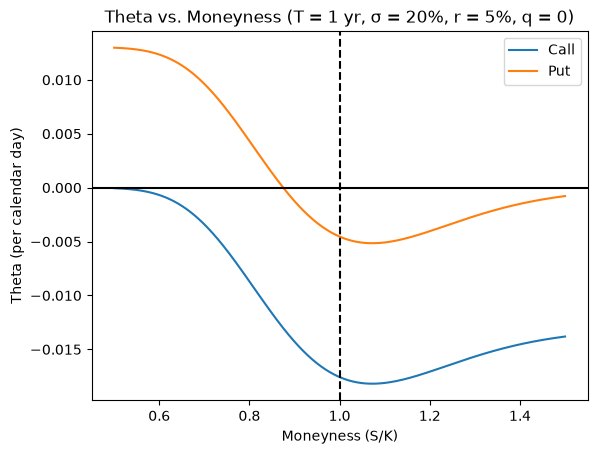

Call minimum: S/K = 1.073, theta = -0.018185
Put minimum:  S/K = 1.073, theta = -0.005155
Put theta is positive for S/K up to 0.874


In [8]:
moneyness = S_GRID / K
call_theta = theta(S_GRID, K, T_BASE, R_BASE, Q_BASE, SIGMA_BASE, "call")
put_theta = theta(S_GRID, K, T_BASE, R_BASE, Q_BASE, SIGMA_BASE, "put")

plt.plot(moneyness, call_theta, label="Call")
plt.plot(moneyness, put_theta, label="Put")
plt.axhline(0, color="black")
plt.axvline(1, color="black", linestyle="--")
plt.xlabel("Moneyness (S/K)")
plt.ylabel("Theta (per calendar day)")
plt.title("Theta vs. Moneyness (T = 1 yr, σ = 20%, r = 5%, q = 0)")
plt.legend()
plt.show()

print(f"Call minimum: S/K = {moneyness[np.argmin(call_theta)]:.3f}, theta = {call_theta.min():.6f}")
print(f"Put minimum:  S/K = {moneyness[np.argmin(put_theta)]:.3f}, theta = {put_theta.min():.6f}")
print(f"Put theta is positive for S/K up to {moneyness[put_theta > 0].max():.3f}")

## Components of Theta vs Moneyness 

- **Varying:** stock price $S$ from 50 to 150, so moneyness $S/K$ runs from 0.5 to 1.5
- **Held constant:** $K = 100$, $T = 1$ year, $\sigma = 20\%$, $r = 5\%$, $q = 0$
- **Shows:** calls (left) and puts (right), each split into its volatility-decay and interest-on-strike parts, with the total Theta for comparison

The dividend part is zero everywhere because $q = 0$ in the base case, so it is not plotted here. Its effect is studied separately in the dividend-yield plot.

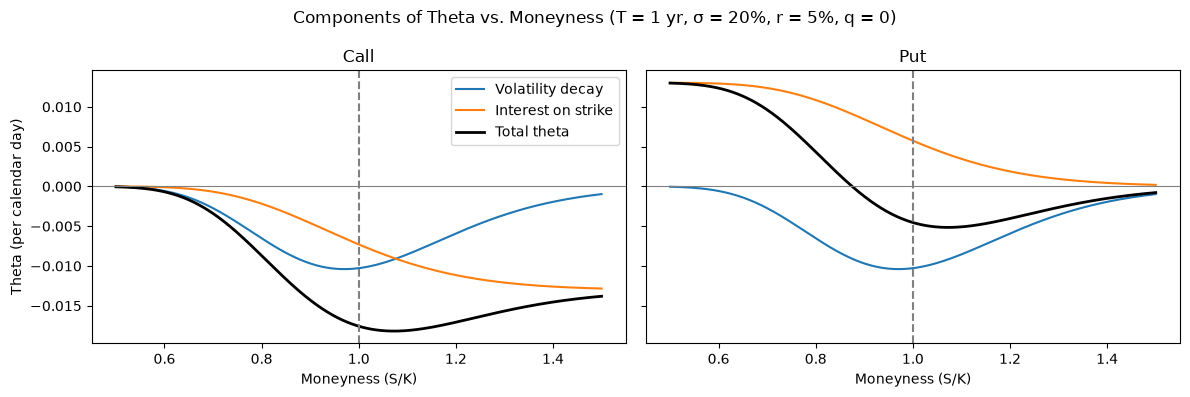

Volatility decay is most negative at S/K = 0.970, value = -0.010397


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for ax, option in zip(axes, ["call", "put"]):
    decay, interest, dividend = theta_parts(S_GRID, K, T_BASE, R_BASE, Q_BASE, SIGMA_BASE, option)

    ax.plot(moneyness, decay, label="Volatility decay")
    ax.plot(moneyness, interest, label="Interest on strike")
    ax.plot(moneyness, decay + interest + dividend, color="black", linewidth=2, label="Total theta")
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.axvline(1, color="gray", linestyle="--")
    ax.set_title(option.capitalize())
    ax.set_xlabel("Moneyness (S/K)")

axes[0].set_ylabel("Theta (per calendar day)")
axes[0].legend()
fig.suptitle("Components of Theta vs. Moneyness (T = 1 yr, σ = 20%, r = 5%, q = 0)")
plt.tight_layout()
plt.show()

decay_part = theta_parts(S_GRID, K, T_BASE, R_BASE, Q_BASE, SIGMA_BASE, "call")[0]
print(f"Volatility decay is most negative at S/K = {moneyness[np.argmin(decay_part)]:.3f}, value = {decay_part.min():.6f}")

### Observations

This plot elucidates the precise portions of total theta made up by the volatility and interest factors based on varying moneyness.

 **Which part dominates where:**
   - Deep OTM: both parts are close to zero, so Theta is close to zero. 
   - ATM: both parts matter. For the call, decay contributes about −0.0103 and interest about −0.0073. For the put, interest offsets part of the decay with about +0.0057.
   - Deep ITM: Owing to near certain exercise, the volatility factor is not as important compared to the interest factor. This makes the difference for puts, where more T gets more interest vs Calls where we lose out. So call Theta approaches −0.0130 and put Theta approaches +0.0130.



## Theta vs Moneyness at Different Maturities

- **Varying:** stock price $S$ from 50 to 150 (moneyness $S/K$ from 0.5 to 1.5), for four maturities: 1 week, 1 month, 3 months and 1 year
- **Held constant:** $K = 100$, $\sigma = 20\%$, $r = 5\%$, $q = 0$
- **Shows:** calls (left) and puts (right)

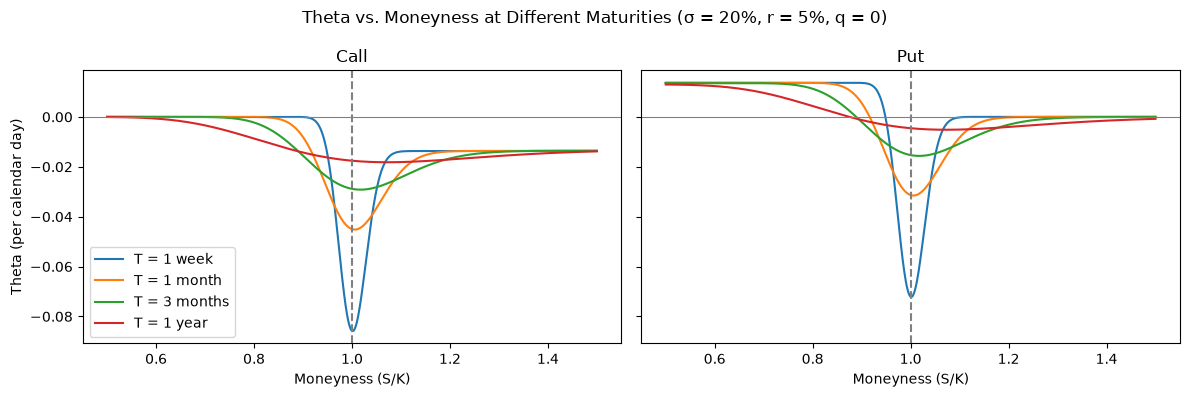

T = 1 week: deepest at S/K = 1.001 (call -0.085875, put -0.072190), put theta positive up to S/K = 0.948
T = 1 month: deepest at S/K = 1.006 (call -0.045178, put -0.031536), put theta positive up to S/K = 0.916
T = 3 months: deepest at S/K = 1.017 (call -0.029173, put -0.015643), put theta positive up to S/K = 0.888
T = 1 year: deepest at S/K = 1.073 (call -0.018185, put -0.005155), put theta positive up to S/K = 0.874


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for ax, option in zip(axes, ["call", "put"]):
    for label, T in MATURITIES.items():
        ax.plot(moneyness, theta(S_GRID, K, T, R_BASE, Q_BASE, SIGMA_BASE, option), label=f"T = {label}")
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.axvline(1, color="gray", linestyle="--")
    ax.set_title(option.capitalize())
    ax.set_xlabel("Moneyness (S/K)")

axes[0].set_ylabel("Theta (per calendar day)")
axes[0].legend()
fig.suptitle("Theta vs. Moneyness at Different Maturities (σ = 20%, r = 5%, q = 0)")
plt.tight_layout()
plt.show()

for label, T in MATURITIES.items():
    call_t = theta(S_GRID, K, T, R_BASE, Q_BASE, SIGMA_BASE, "call")
    put_t = theta(S_GRID, K, T, R_BASE, Q_BASE, SIGMA_BASE, "put")
    print(f"T = {label}: deepest at S/K = {moneyness[np.argmin(call_t)]:.3f} "
          f"(call {call_t.min():.6f}, put {put_t.min():.6f}), "
          f"put theta positive up to S/K = {moneyness[put_t > 0].max():.3f}")

## Theta vs Time to Maturity

- **Varying:** time to maturity, from 1 day to 2 years in steps of one calendar day
- **Held constant:** $K = 100$, $\sigma = 20\%$, $r = 5\%$, $q = 0$, at three moneyness levels: $S/K = 0.9$, $1.0$ and $1.1$
- **Shows:** calls (left) and puts (right). For calls, $S/K = 0.9$ is OTM and $1.1$ is ITM; for puts it is the reverse.

The x-axis uses a log scale, so that the last few weeks before expiry, where Theta changes fastest, are not squeezed into a sliver at the left edge. Moving left along the axis means time passing, i.e. getting closer to expiry.

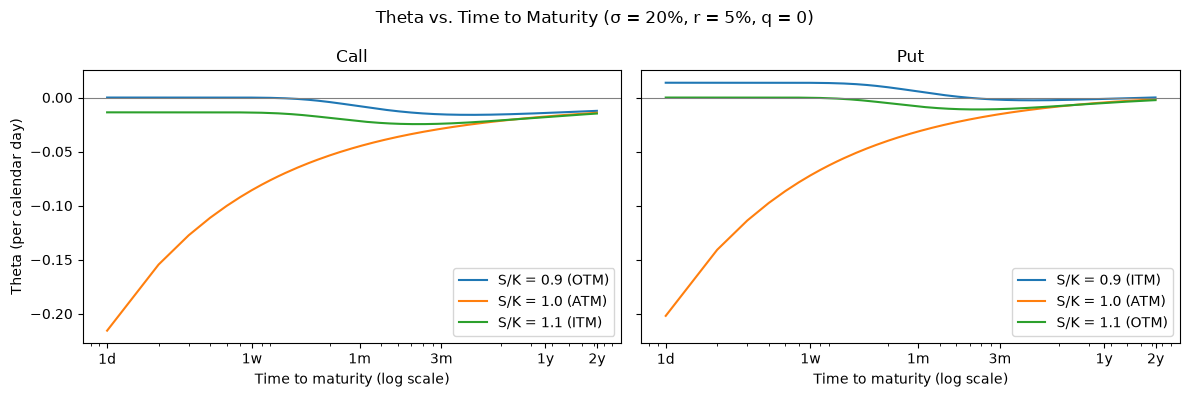

,option,S/K,type,1 day,1 week,1 month,1 year,2 years,most negative at (days)
0,call,0.9,OTM,-0.000000,-0.000063,-0.008084,-0.014286,-0.012312,133
1,call,1.0,ATM,-0.215672,-0.085789,-0.044988,-0.017573,-0.014076,1
2,call,1.1,ITM,-0.013697,-0.013879,-0.021912,-0.018115,-0.014797,66
3,put,0.9,ITM,0.013697,0.013623,0.005558,-0.001256,0.000083,140
4,put,1.0,ATM,-0.201975,-0.072103,-0.031346,-0.004542,-0.001681,1
5,put,1.1,OTM,-0.000000,-0.000193,-0.008270,-0.005085,-0.002402,67


In [14]:
days = T_GRID * DAYS_PER_YEAR
labels = {"call": {0.9: "OTM", 1.0: "ATM", 1.1: "ITM"},
          "put": {0.9: "ITM", 1.0: "ATM", 1.1: "OTM"}}

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
rows = []

for ax, option in zip(axes, ["call", "put"]):
    for m in MONEYNESS_LEVELS:
        th = theta(m * K, K, T_GRID, R_BASE, Q_BASE, SIGMA_BASE, option)
        ax.plot(days, th, label=f"S/K = {m} ({labels[option][m]})")
        # th[i] is Theta with i + 1 days to maturity
        rows.append({"option": option, "S/K": m, "type": labels[option][m],
                     "1 day": th[0], "1 week": th[6], "1 month": th[29],
                     "1 year": th[364], "2 years": th[729],
                     "most negative at (days)": np.argmin(th) + 1})

    ax.set_xscale("log")
    ax.set_xticks([1, 7, 30, 90, 365, 730], ["1d", "1w", "1m", "3m", "1y", "2y"])
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.set_title(option.capitalize())
    ax.set_xlabel("Time to maturity (log scale)")
    ax.legend()

axes[0].set_ylabel("Theta (per calendar day)")
fig.suptitle("Theta vs. Time to Maturity (σ = 20%, r = 5%, q = 0)")
plt.tight_layout()
plt.show()

pd.DataFrame(rows).round(6)

## Theta vs Moneyness at Different Volatilities

- **Varying:** stock price $S$ from 50 to 150 (moneyness $S/K$ from 0.5 to 1.5), for three volatilities: $\sigma = 10\%$, $20\%$ and $40\%$
- **Held constant:** $K = 100$, $T = 1$ year, $r = 5\%$, $q = 0$
- **Shows:** calls (left) and puts (right)

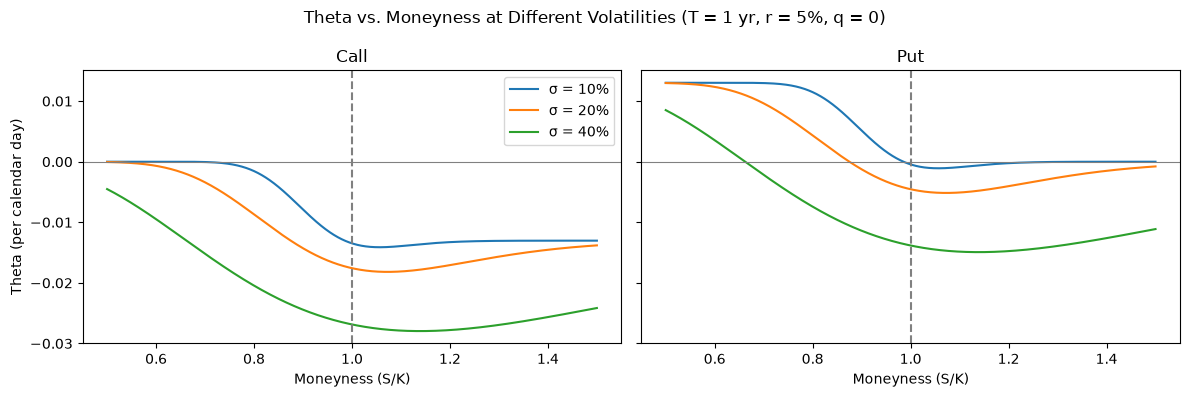

σ = 10%: deepest at S/K = 1.057 (call -0.014116, put -0.001086), put theta positive up to S/K = 0.985
σ = 20%: deepest at S/K = 1.073 (call -0.018185, put -0.005155), put theta positive up to S/K = 0.874
σ = 40%: deepest at S/K = 1.139 (call -0.027955, put -0.014925), put theta positive up to S/K = 0.662


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for ax, option in zip(axes, ["call", "put"]):
    for sigma in SIGMAS:
        ax.plot(moneyness, theta(S_GRID, K, T_BASE, R_BASE, Q_BASE, sigma, option), label=f"σ = {sigma:.0%}")
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.axvline(1, color="gray", linestyle="--")
    ax.set_title(option.capitalize())
    ax.set_xlabel("Moneyness (S/K)")

axes[0].set_ylabel("Theta (per calendar day)")
axes[0].legend()
fig.suptitle("Theta vs. Moneyness at Different Volatilities (T = 1 yr, r = 5%, q = 0)")
plt.tight_layout()
plt.show()

for sigma in SIGMAS:
    call_t = theta(S_GRID, K, T_BASE, R_BASE, Q_BASE, sigma, "call")
    put_t = theta(S_GRID, K, T_BASE, R_BASE, Q_BASE, sigma, "put")
    print(f"σ = {sigma:.0%}: deepest at S/K = {moneyness[np.argmin(call_t)]:.3f} "
          f"(call {call_t.min():.6f}, put {put_t.min():.6f}), "
          f"put theta positive up to S/K = {moneyness[put_t > 0].max():.3f}")

## Theta vs Moneyness at Different Interest Rates

- **Varying:** stock price $S$ from 50 to 150 (moneyness $S/K$ from 0.5 to 1.5), for three risk-free rates: $r = 0\%$, $5\%$ and $10\%$
- **Held constant:** $K = 100$, $T = 1$ year, $\sigma = 20\%$, $q = 0$
- **Shows:** calls (left) and puts (right)

$r = 0\%$ is included as a baseline: with $r = q = 0$, the interest and dividend parts both vanish, so call and put Theta should be identical.

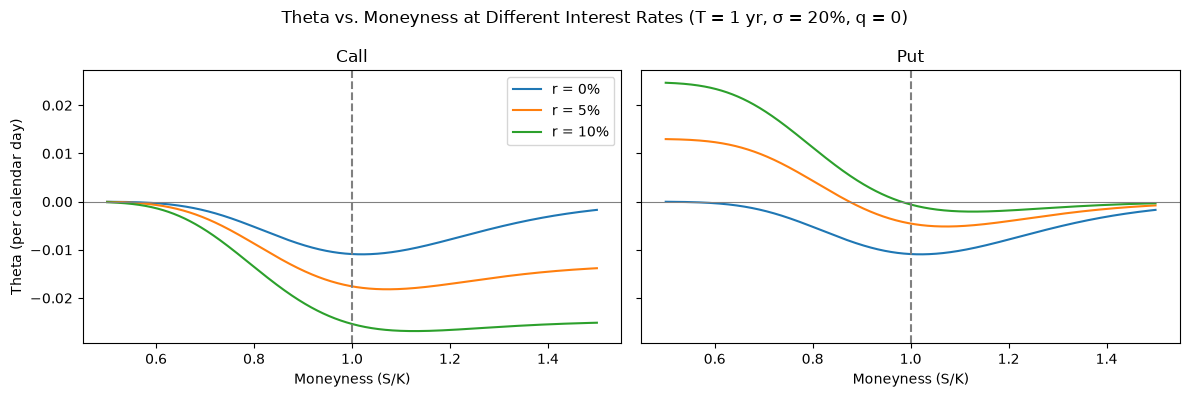

r = 0%: deepest at S/K = 1.020 (call -0.010930, put -0.010930), put theta positive nowhere
r = 5%: deepest at S/K = 1.073 (call -0.018185, put -0.005155), put theta positive up to S/K = 0.874
r = 10%: deepest at S/K = 1.127 (call -0.026855, put -0.002065), put theta positive up to S/K = 0.980


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for ax, option in zip(axes, ["call", "put"]):
    for rate in RATES:
        ax.plot(moneyness, theta(S_GRID, K, T_BASE, rate, Q_BASE, SIGMA_BASE, option), label=f"r = {rate:.0%}")
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.axvline(1, color="gray", linestyle="--")
    ax.set_title(option.capitalize())
    ax.set_xlabel("Moneyness (S/K)")

axes[0].set_ylabel("Theta (per calendar day)")
axes[0].legend()
fig.suptitle("Theta vs. Moneyness at Different Interest Rates (T = 1 yr, σ = 20%, q = 0)")
plt.tight_layout()
plt.show()

for rate in RATES:
    call_t = theta(S_GRID, K, T_BASE, rate, Q_BASE, SIGMA_BASE, "call")
    put_t = theta(S_GRID, K, T_BASE, rate, Q_BASE, SIGMA_BASE, "put")
    positive = moneyness[put_t > 0]
    put_range = f"up to S/K = {positive.max():.3f}" if positive.size > 0 else "nowhere"
    print(f"r = {rate:.0%}: deepest at S/K = {moneyness[np.argmin(call_t)]:.3f} "
          f"(call {call_t.min():.6f}, put {put_t.min():.6f}), put theta positive {put_range}")

## Theta vs Moneyness at Different Dividend Yields

- **Varying:** stock price $S$ from 50 to 150 (moneyness $S/K$ from 0.5 to 1.5), for three dividend yields: $q = 0\%$, $5\%$ and $10\%$
- **Held constant:** $K = 100$, $T = 1$ year, $\sigma = 20\%$, $r = 5\%$
- **Shows:** calls (left) and puts (right)

$q = 0\%$ matches the base case. With $r$ fixed at 5%, the dividend part now competes with the interest part, so the sign of Theta can change for calls as well as puts.

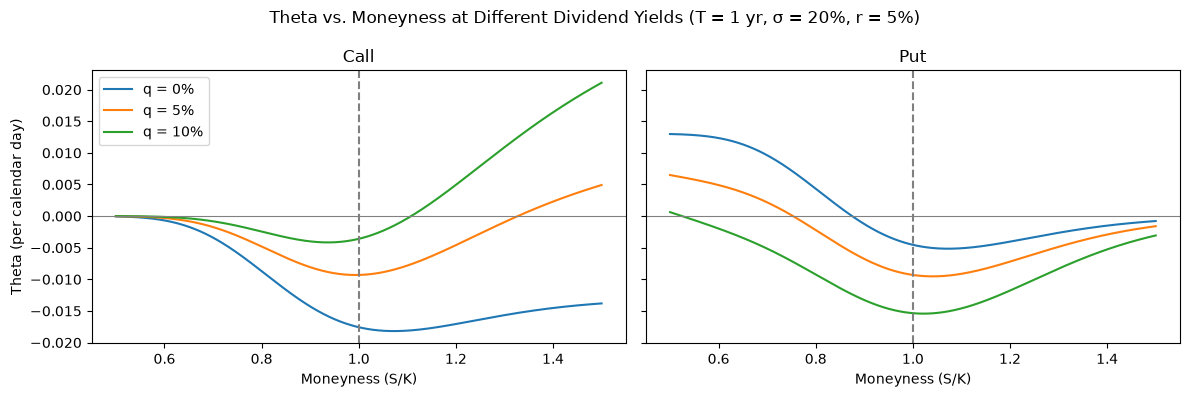

q = 0%: call deepest at S/K = 1.073 (-0.018185), put deepest at S/K = 1.073 (-0.005155)
        call theta positive nowhere, put theta positive up to S/K = 0.874
q = 5%: call deepest at S/K = 0.994 (-0.009313), put deepest at S/K = 1.041 (-0.009531)
        call theta positive from S/K = 1.328, put theta positive up to S/K = 0.753
q = 10%: call deepest at S/K = 0.937 (-0.004161), put deepest at S/K = 1.022 (-0.015426)
        call theta positive from S/K = 1.108, put theta positive up to S/K = 0.525


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for ax, option in zip(axes, ["call", "put"]):
    for q in DIV_YIELDS:
        ax.plot(moneyness, theta(S_GRID, K, T_BASE, R_BASE, q, SIGMA_BASE, option), label=f"q = {q:.0%}")
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.axvline(1, color="gray", linestyle="--")
    ax.set_title(option.capitalize())
    ax.set_xlabel("Moneyness (S/K)")

axes[0].set_ylabel("Theta (per calendar day)")
axes[0].legend()
fig.suptitle("Theta vs. Moneyness at Different Dividend Yields (T = 1 yr, σ = 20%, r = 5%)")
plt.tight_layout()
plt.show()

for q in DIV_YIELDS:
    call_t = theta(S_GRID, K, T_BASE, R_BASE, q, SIGMA_BASE, "call")
    put_t = theta(S_GRID, K, T_BASE, R_BASE, q, SIGMA_BASE, "put")
    call_pos = moneyness[call_t > 0]
    put_pos = moneyness[put_t > 0]
    call_range = f"from S/K = {call_pos.min():.3f}" if call_pos.size > 0 else "nowhere"
    put_range = f"up to S/K = {put_pos.max():.3f}" if put_pos.size > 0 else "nowhere"
    print(f"q = {q:.0%}: call deepest at S/K = {moneyness[np.argmin(call_t)]:.3f} ({call_t.min():.6f}), "
          f"put deepest at S/K = {moneyness[np.argmin(put_t)]:.3f} ({put_t.min():.6f})")
    print(f"        call theta positive {call_range}, put theta positive {put_range}")

## Summary

All Theta values are per calendar day, i.e. $\Theta_{\text{year}}/365$. Unless stated otherwise: $K = 100$, $T = 1$ year, $\sigma = 20\%$, $r = 5\%$, $q = 0$.

### Where Theta reaches its extremes

- In the base case, both call and put Theta are most negative at $S/K \approx 1.07$ (call −0.0182, put −0.0052), not exactly at ATM. The volatility-decay part peaks slightly below ATM ($S/K \approx 0.97$), and the call's interest part pulls the combined minimum to the right.
- The deepest point moves toward ATM as expiry approaches (1.001 at 1 week), and further into the money with higher volatility (1.139 at $\sigma = 40\%$) or higher rates (1.127 at $r = 10\%$). Dividends pull the call's deepest point the other way (about 0.93 at $q = 10\%$).
- The most positive values occur for deep in-the-money puts (about +0.013 in the base case, +0.025 at $r = 10\%$) and for deep in-the-money calls when dividends are high (about +0.021 at $S/K = 1.5$, $q = 10\%$).

### Sign, and calls vs puts

- With $q = 0$, call Theta is negative everywhere, while put Theta is positive for deep in-the-money puts ($S/K < 0.875$ in the base case).
- Call Theta minus put Theta equals $\frac{qSe^{-qT} - rKe^{-rT}}{365}$. When $q = 0$ this is a constant (−0.0130 in the base case), so the two curves have the same shape. When $q > 0$ it depends on $S$, and the shapes differ.
- Deep in-the-money call Theta becomes positive when $qSe^{-qT} > rKe^{-rT}$.

### Across moneyness

- **ATM:** volatility decay is largest, so Theta is most negative near the money.
- **Deep OTM:** Theta goes to zero, since there is little time value left and exercise is unlikely.
- **Deep ITM:** volatility decay fades and only the interest and dividend parts remain. Call Theta approaches $\frac{qSe^{-qT} - rKe^{-rT}}{365}$ and put Theta approaches $\frac{rKe^{-rT} - qSe^{-qT}}{365}$.

### Effect of each parameter

- **Time to maturity:** ATM decay grows without limit as expiry approaches (−0.0176 at 1 year to −0.2157 at 1 day), due to the $\frac{1}{\sqrt{T}}$ factor, and the decay becomes concentrated in a narrow band around ATM.
- **Volatility:** higher $\sigma$ gives deeper and wider decay, and shrinks the region of positive put Theta.
- **Risk-free rate:** higher $r$ makes calls decay faster and puts slower, and widens the region of positive put Theta. The effect is concentrated on the in-the-money side.
- **Dividend yield:** higher $q$ makes calls decay slower, and can make deep in-the-money call Theta positive. It makes puts decay faster. This is the mirror image of the rate effect.

### Turning points and nonlinearities

- OTM Theta is most negative at intermediate maturities (about 133 days for the OTM call, 67 days for the OTM put), and close to zero both near expiry and at long maturities.
- ITM put Theta changes sign with maturity: positive near expiry, negative at intermediate maturities (most negative at about 140 days), and close to zero at 2 years.
- Curves for different maturities cross: near ATM, the shortest maturities decay fastest; away from ATM, intermediate maturities do.
- Theta changes sign across moneyness: put Theta crosses zero at $S/K \approx 0.875$ in the base case, and with dividends call Theta crosses zero at $S/K \approx 1.33$ ($q = 5\%$) and $1.11$ ($q = 10\%$).

### Comparison with class

- **Matches:** Theta is negative for most long options, which makes it favourable to option sellers; decay accelerates as expiry approaches; and the formula reduces to the course formula when $q = 0$.
- **Extends:** with $r > 0$, deep in-the-money European puts have positive Theta, and with $q > 0$ deep in-the-money calls can too. So long options *usually*, but not always, have negative Theta.